# Time Series

Our class is helping a student bike club plan a ride across Seattle's Fremont Bridge. Maya wants to know when traffic is busiest. Luis asks whether a quiet-looking hour means the bridge was empty or the counter stopped working. Later, the club asks what an air-quality sensor can tell us about days outdoors.

A **time series** connects measurements of a process to when they happened. We will start with six invented readings that we can check by hand, then apply the same tools to real bridge and air-quality records.

By the end, you can:

- Parse and sort a time index; select dates with `.loc`.
- Use `resample` to summarize observations and reveal trends.
- Distinguish a timeline from a repeating calendar pattern.
- Check missing readings and explain what interpolation assumes.
- Connect a chart's claims to how its data were collected.

At each **Your turn**, try the code, then compare your reasoning with a partner.

## What does one row mean?

A **timestamp** identifies a date and time, such as `2024-09-02 08:00:00`. It might label a measurement taken at that moment or a total for a **time interval**, such as the hour starting at 8:00. Read the dataset description before choosing a summary.

| Example | What one value measures | A useful daily summary |
| --- | --- | --- |
| Bridge counter | Crossings during an hour | Sum of hourly counts |
| Air-quality sensor | Particle concentration at a reading | Mean or maximum concentration |
| Earthquake record | Magnitude of an event | Largest magnitude or number of events |

Hourly readings have a regular **frequency**; earthquakes arrive irregularly. Neighboring rows do not always represent the same amount of elapsed time. Our practice file contains only 8:00 and 9:00 on each of three days. Its totals describe the **observed hours**, not whole days.

In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
%matplotlib inline

csv = """Date,East,West
2024-09-02 08:00:00,4,6
2024-09-02 09:00:00,8,12
2024-09-03 08:00:00,12,18
2024-09-03 09:00:00,16,24
2024-09-04 08:00:00,20,30
2024-09-04 09:00:00,24,36
"""
bikes = pd.read_csv(io.StringIO(csv), index_col="Date", parse_dates=["Date"])
bikes = bikes.sort_index()
bikes["Total"] = bikes["East"] + bikes["West"]
bikes

,East,West,Total
Date,,,
2024-09-02 08:00:00,4,6,10
2024-09-02 09:00:00,8,12,20
2024-09-03 08:00:00,12,18,30
2024-09-03 09:00:00,16,24,40
2024-09-04 08:00:00,20,30,50
2024-09-04 09:00:00,24,36,60


## Give the index a clock

`index_col="Date"` chooses the row labels, and `parse_dates=["Date"]` converts their text to dates. Neither option promises chronological order: `sort_index()` returns rows from earliest to latest, so we save its result. Sorting matters when a line plot connects readings in sequence.

The whole index is a **DatetimeIndex**; one label is a **Timestamp**. A dtype such as `datetime64[us]` uses microsecond storage resolution (`us`), while other pandas versions may show nanoseconds (`ns`). This describes precision, not a date format. Use year-first dates in your own examples to avoid ambiguous strings such as `09/02/2024`.

In [2]:
print(bikes.index)
print(type(bikes.index[0]).__name__)
assert bikes.index.is_monotonic_increasing

DatetimeIndex(['2024-09-02 08:00:00', '2024-09-02 09:00:00',
               '2024-09-03 08:00:00', '2024-09-03 09:00:00',
               '2024-09-04 08:00:00', '2024-09-04 09:00:00'],
              dtype='datetime64[us]', name='Date', freq=None)
Timestamp


Dates support arithmetic: subtracting timestamps returns a **Timedelta**, or duration. Predict the gap below before running it. These readings fall on consecutive dates, but are they one hour apart?

In [3]:
start = pd.Timestamp("2024-09-02 09:00:00")
end = pd.Timestamp("2024-09-03 08:00:00")
end - start

Timedelta('0 days 23:00:00')

The gap is **23 hours**. Row position tells us which observation comes next; timestamps tell us how much time passed. Subtracting the original date strings would not work because Python treats them as text.

## Select dates with loc

Maya wants to know how September 2's morning compares with September 3's. `.loc[row, column]` selects existing readings by their labels. A complete timestamp selects one observation in this dataset; a day, month, or year string selects all matching timestamps.

Predict the number of values in each result before running it.

In [4]:
bikes.loc["2024-09-02 08:00:00", "Total"]

np.int64(10)

In [5]:
bikes.loc["2024-09-02", "Total"]

Date
2024-09-02 08:00:00    10
2024-09-02 09:00:00    20
Name: Total, dtype: int64

In [6]:
bikes.loc["2024-09-02":"2024-09-03", "Total"]

Date
2024-09-02 08:00:00    10
2024-09-02 09:00:00    20
2024-09-03 08:00:00    30
2024-09-03 09:00:00    40
Name: Total, dtype: int64

The results contain one value, two hourly values, and four hourly values respectively. Pandas label slices include the **end date**, unlike a Python list's stopping position. `.loc["2024-09", "Total"]` would keep all six September readings.

**Your turn (2 minutes):** Luis wants to know the West-side counts for September 3 **through** September 4. Select those readings. How many values should the result contain? Does selecting dates combine their counts?

In [7]:
# Select the West counts for both dates.

## Resample: group observations into time buckets

Maya wants to know how many crossings were recorded on each date. Just as `groupby("category")` groups data by matching category names, `resample("frequency")` groups time-series data into custom time buckets, such as hours, days, weeks, or months, and lets us combine values or fill gaps in those periods.

Here, `resample("D")` uses the time index to group each date's readings, `["Total"]` selects the counts, and `.sum()` adds them. Choosing the time bucket and choosing the summary are separate decisions.

In [8]:
daily = bikes.resample("D")["Total"].sum(min_count=1)
daily

Date
2024-09-02     30
2024-09-03     70
2024-09-04    110
Freq: D, Name: Total, dtype: int64

Six readings become **three** summaries: 10 + 20 = 30, 30 + 40 = 70, and 50 + 60 = 110. Each label is midnight at the start of the day, not a new midnight measurement. `min_count=1` requires at least one valid reading; we will see why that matters when data are missing.

`.loc` keeps original observations; `resample` calculates summaries. The September 2 selection contained 10 and 20; its daily sum is 30. Neither changes `bikes` unless we assign the result back to it.

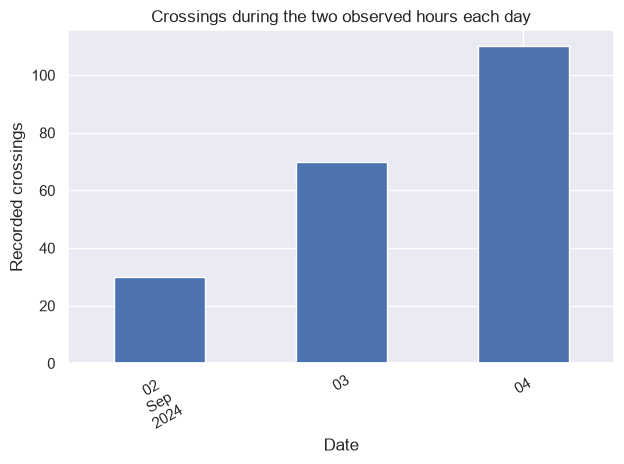

In [9]:
daily.plot.bar(
    title="Crossings during the two observed hours each day",
    xlabel="Date", ylabel="Recorded crossings", rot=30,
)
plt.tight_layout()
plt.show()
assert daily.tolist() == [30, 70, 110]

Replacing `.sum()` with `.mean()` would give **15 crossings per observed hour** on September 2. Summing answers how many crossings were recorded; averaging answers what a typical recorded hour looked like. Adding hourly temperatures or particle concentrations would not give a useful daily temperature or concentration.

| Time rule | Groups |
| --- | --- |
| `"h"` | Hours |
| `"D"` | Calendar days |
| `"W"` | Weeks ending Sunday |
| `"MS"` | Calendar months, labeled at month start |

Calendar intervals have different lengths: a month is not always 30 days. Weekly groups normally run Monday through Sunday. Always check the units and interval behind a plotted value.

### Your turn: find the busiest observed hour each day (3 minutes)

Maya wants to know how crowded the busiest hour was on each date. A daily sum does not answer that question. Use daily resampling to find the **maximum** hourly `Total`. Save it as `daily_peaks`, then plot it in the next cell with a title and units.

Compare your peaks with `daily`. What does each summary tell Maya, and what does each leave out? Could either summary tell her whether 8:00 or 9:00 was busier without returning to the hourly readings?

In [10]:
# Compute daily_peaks using daily resampling and max().

In [11]:
# Plot daily_peaks with a title and units.

**Check your reasoning:** The peaks are **20, 40, and 60 crossings in an observed hour**. The daily sums are 30, 70, and 110 crossings across both observed hours. A maximum preserves the busiest hour's count, but not its timestamp or the other hour's count.

### Compare consecutive summaries

Luis wants to know how much the recorded total changed from one day to the next. `.diff()` subtracts the previous row's value from the current one. With a list, the same calculation would be `values[i] - values[i - 1]`. Predict the two changes in our daily totals, 30, 70, and 110.

In [12]:
daily.diff()

Date
2024-09-02     NaN
2024-09-03    40.0
2024-09-04    40.0
Freq: D, Name: Total, dtype: float64

The result is **NaN, 40, 40**. The first day has no previous value to compare with. Here the rows are consecutive days because we resampled daily. On an irregular time series, `.diff()` still compares neighboring rows even when different amounts of time passed. Check the time index before calling a change "per day."

## Missing observations are not zero

Luis wants to know whether a missing daily total means nobody crossed. Imagine the counter stopped recording for all of September 3. Remove those rows, then resample.

In [13]:
with_gap = bikes.loc[bikes.index.day != 3]
with_gap.resample("D")["Total"].sum(min_count=1)

Date
2024-09-02     30.0
2024-09-03      NaN
2024-09-04    110.0
Freq: D, Name: Total, dtype: float64

September 3 is `NaN`: we have no readings. Zero would claim that we measured no crossings. Without `min_count=1`, an empty group's sum would be zero and hide the gap.

One valid hour still satisfies `min_count=1`, so a non-missing sum does **not** guarantee a complete day. Both `sum()` and `mean()` normally skip missing values. Count valid readings to check the coverage behind a summary.

### Your turn: catch an incomplete day (3 minutes)

This time, only September 3 at 09:00 is missing. Run the setup, then calculate daily sums with `min_count=1` as `partial_totals` and valid hourly counts with `.count()` as `partial_counts`.

Maya wants to know whether the smaller September 3 total proves that traffic fell. Use the counts to explain what she can conclude. Remember that our invented file expects two readings per day.

In [14]:
partial_day = bikes.loc[bikes.index != pd.Timestamp("2024-09-03 09:00:00")]
# Compute partial_totals and partial_counts without changing bikes.

**Check your reasoning:** The counts are **2, 1, 2**. September 3's recorded total is 30 instead of 70 because an hour is missing. We cannot infer a fall in traffic from this incomplete total. `isna()` identifies missing values; `dropna()` removes them and `fillna(0)` replaces them. Those choices change what a reader sees; neither recovers the missing observation.

### More rows do not mean more measurements

Requesting a finer frequency is **upsampling**. `.asfreq("30min")` places our hourly observations on a 30-minute grid. Predict the 08:30 value below: did the counter record anything then?

In [15]:
bikes.loc["2024-09-02", "Total"].asfreq("30min")

Date
2024-09-02 08:00:00    10.0
2024-09-02 08:30:00     NaN
2024-09-02 09:00:00    20.0
Freq: 30min, Name: Total, dtype: float64

There are three time slots but only two observations: **10, NaN, 20**. Creating a slot cannot tell us what happened between readings. Filling it requires an assumption; filling it with zero would claim that no crossings were measured.

## Real bridge data: reveal the trend

Maya wants to know how traffic changed through 2017. [bicycles.csv](bicycles.csv) contains hourly East and West counts from Seattle's Fremont Bridge, October 2012 through March 2019. These are crossings, so one person can appear more than once.

The file arrives newest first, with month/day/year dates and a 12-hour clock. Parse that format explicitly, then sort. Adding East and West leaves `Total` missing if either side is missing. Keep `bicycles.csv` and `seattle_air.csv` in the same folder as this notebook.

In [16]:
bicycles = pd.read_csv(
    "bicycles.csv", index_col="Date", parse_dates=["Date"],
    date_format="%m/%d/%Y %I:%M:%S %p",
)
bicycles = bicycles.sort_index()
bicycles["Total"] = bicycles["East"] + bicycles["West"]
year_bikes = bicycles.loc["2017"]
year_bikes.head()

,East,West,Total
Date,,,
2017-01-01 00:00:00,0.0,5.0,5.0
2017-01-01 01:00:00,5.0,14.0,19.0
2017-01-01 02:00:00,1.0,0.0,1.0
2017-01-01 03:00:00,0.0,2.0,2.0
2017-01-01 04:00:00,0.0,1.0,1.0


Combining smaller intervals into larger ones is **downsampling**. A main reason to downsample is to reduce short-term noise so we can see broader trends instead of every fluctuation in individual readings. The **granularity** is how much time each value represents.

Compare the hourly graph and weekly totals below. Weekly sums make longer changes easier to see, but hide busy hours and daily peaks. A small weekly sum could also reflect missing readings or a partial week at the dataset's edge. `min_count=1` prevents an entirely empty week from becoming zero; it does not guarantee a complete week.

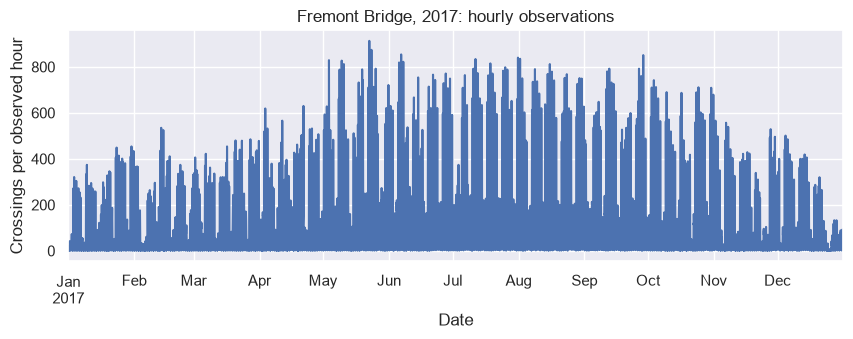

In [17]:
year_bikes["Total"].plot(
    figsize=(10, 3), title="Fremont Bridge, 2017: hourly observations",
    xlabel="Date", ylabel="Crossings per observed hour",
)
plt.show()

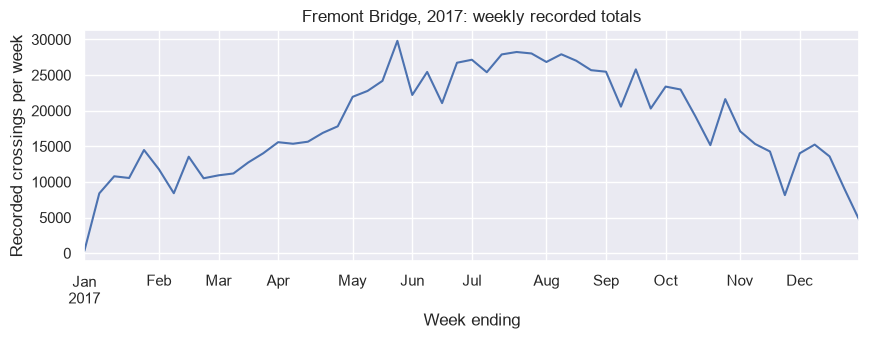

In [18]:
year_weekly = year_bikes["Total"].resample("W").sum(min_count=1)
year_weekly.plot(
    figsize=(10, 3), title="Fremont Bridge, 2017: weekly recorded totals",
    xlabel="Week ending", ylabel="Recorded crossings per week",
)
plt.show()

**Partner check (1 minute):** name one pattern easier to see in the weekly graph and one detail it hides. Why do the two vertical axes have different units? Which view would help Maya choose a quiet hour?

### Groupby vs. resample: the same month across different years

Daily and weekly resampling kept the observations on a timeline. Now compare that with grouping the same calendar month across different years.

Maya wants to know how traffic changed month by month across the years. Luis wants to know which calendar months are typically busiest. Use the **whole bicycle record**, already loaded as `bicycles`, to compare three views. The summaries below are means per **observed hour**, not monthly crossing totals.

First, look at the hourly observations before combining them.

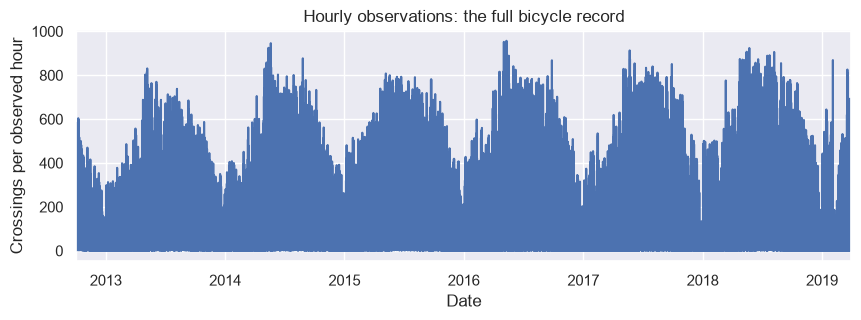

In [19]:
bicycles["Total"].plot(
    figsize=(10, 3), title="Hourly observations: the full bicycle record",
    xlabel="Date", ylabel="Crossings per observed hour",
)
plt.show()
# Notice: individual hours are noisy, but their dates still include the year.

`resample("MS")` groups readings into calendar months, labeled at each month's start. January 2013 and January 2014 remain **separate points** on the timeline. Averaging reduces hourly noise so longer changes are easier to see.

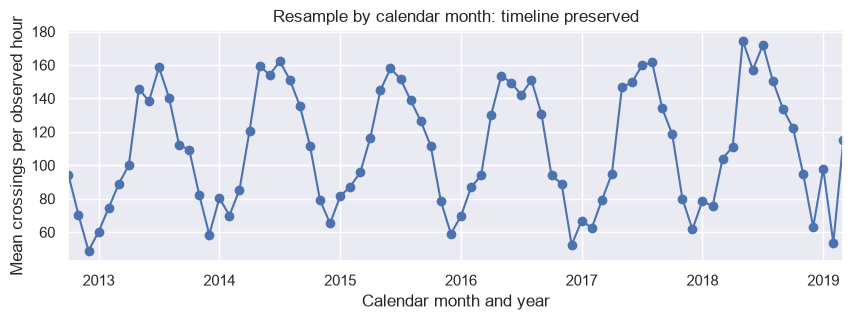

In [20]:
monthly = bicycles["Total"].resample("MS").mean()
monthly.plot(
    figsize=(10, 3), marker="o", title="Resample by calendar month: timeline preserved",
    xlabel="Calendar month and year", ylabel="Mean crossings per observed hour",
)
plt.show()
# Notice: each year-month has its own point; different years' Januaries stay separate.

`bicycles.index.month` extracts only month numbers 1 through 12. Grouping by those numbers combines **all Januaries across years**, all Februaries, and so on. Predict how many values this produces and whether its horizontal axis will still show years.

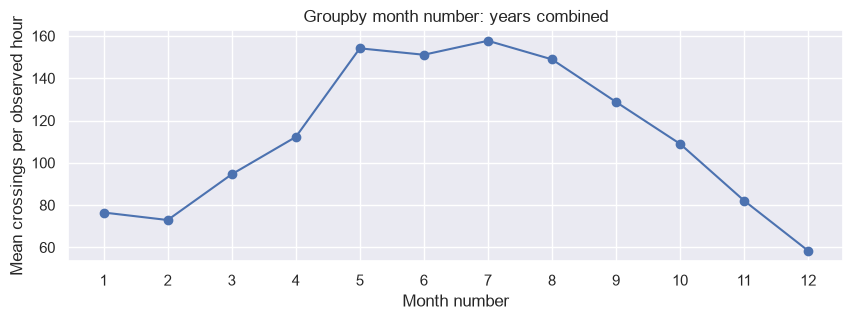

In [21]:
month_grouped = bicycles.groupby(bicycles.index.month)["Total"].mean()
month_grouped.plot(
    figsize=(10, 3), marker="o", title="Groupby month number: years combined",
    xlabel="Month number", ylabel="Mean crossings per observed hour", xticks=range(1, 13),
)
plt.show()
# Notice: there are only 12 values; each month combines its readings from every year.

The resampled graph preserves **year and month**; the month-number graph has **12 values** and no year labels. It reveals a recurring calendar pattern, but cannot tell Maya whether a particular January got busier than the previous January.

| Question | Grouping rule |
| --- | --- |
| How did recorded traffic change month by month over time? | `resample("MS")` |
| What was a typical recorded hour in each month of the year? | `groupby(bicycles.index.month)` |

The grouping key makes the difference: `groupby` could also keep years separate if we grouped by **both year and month**. Here we deliberately supply only month numbers.

**Partner check (1 minute):** which graph answers Maya's question, and which answers Luis's? Both use means, so why do they tell different stories? Unequal coverage can affect either mean; partial first and last months should not be mistaken for fully observed periods.

## Timeline or repeating pattern?

A **trend** is a longer-term rise or fall. **Seasonality** is a recurring calendar pattern, such as differences between weekdays or clock hours. `resample("W")` keeps weeks in chronological order. Grouping by `index.day_of_week` combines matching weekdays across the year; grouping by `index.month` would combine matching months across years.

Maya wants to know which weekday had the highest average daily traffic in 2017. First sum each day's counts, then average those totals by weekday. Keep days with 24 valid hourly readings so a missing hour does not make a day look quiet. This also excludes days with 23 or 25 readings around local clock changes. Exclusion can bias the comparison if missing readings are related to traffic.

In [22]:
year_daily = year_bikes["Total"].resample("D").sum(min_count=1)
hour_counts = year_bikes["Total"].resample("D").count()
complete_days = year_daily.loc[hour_counts == 24]
weekday_summary = complete_days.groupby(complete_days.index.day_of_week).agg(["mean", "count"])
weekday_summary = weekday_summary.reindex(range(7))
weekday_summary.index = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary.columns = ["Mean daily crossings", "Days included"]
weekday_summary

,Mean daily crossings,Days included
Monday,3103.807692,52
Tuesday,3286.250000,52
Wednesday,3305.153846,52
Thursday,3074.634615,52
Friday,2919.500000,52
Saturday,1459.576923,52
Sunday,1358.750000,52


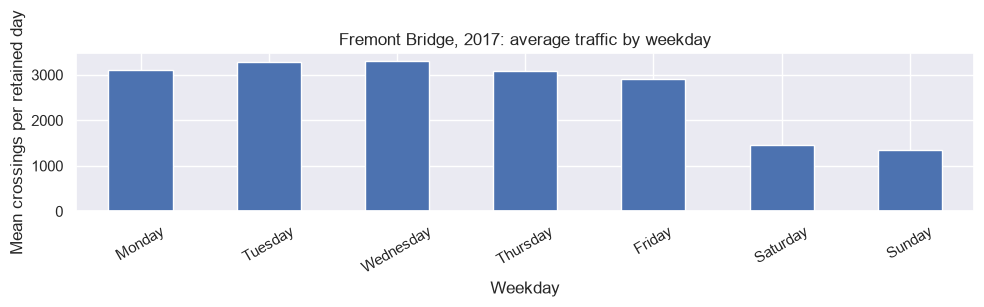

In [23]:
weekday_summary["Mean daily crossings"].plot.bar(
    figsize=(10, 3), rot=30, title="Fremont Bridge, 2017: average traffic by weekday",
    xlabel="Weekday", ylabel="Mean crossings per retained day",
)
plt.tight_layout()
plt.show()

**Your turn (2 minutes):** Maya wants to know which weekday to choose for a quieter ride. Use the chart and `Days included` to make a recommendation. State the year, bridge, and what was averaged. Why does an average over whole days leave her question about a particular hour unanswered? These counts do not tell us people's trip purposes or guarantee next year's pattern.

## Air quality: what does an average hide?

The club also wants to know whether a short spike or sustained pollution caused a high reading. [seattle_air.csv](seattle_air.csv) is a historical snapshot from the Puget Sound Clean Air Agency's Seattle-Duwamish sensor, April 2017 through April 2022. It records hourly **PM2.5**, a concentration of fine particles in micrograms per cubic meter (µg/m³).

A concentration calls for a mean or maximum, not a sum. Compare daily means and peaks, then check the number of valid readings behind them. The first and last years are partial, and this sensor describes one location; neither a full year's coverage nor conditions along the whole ride are guaranteed.

In [24]:
seattle_air = pd.read_csv("seattle_air.csv", index_col="Time", parse_dates=["Time"]).sort_index()
air_daily = seattle_air["PM2.5"].resample("D").agg(["mean", "max", "count"])
air_daily.head()

,mean,max,count
Time,,,
2017-04-06,6.433333,9.3,24
2017-04-07,6.582609,12.6,23
2017-04-08,6.508333,9.9,24
2017-04-09,6.429167,8.1,24
2017-04-10,6.425000,9.3,24


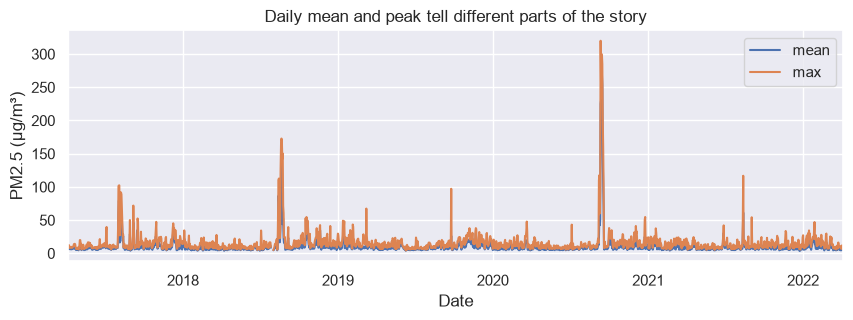

In [25]:
air_daily[["mean", "max"]].plot(
    figsize=(10, 3), title="Daily mean and peak tell different parts of the story",
    xlabel="Date", ylabel="PM2.5 (µg/m³)",
)
plt.show()

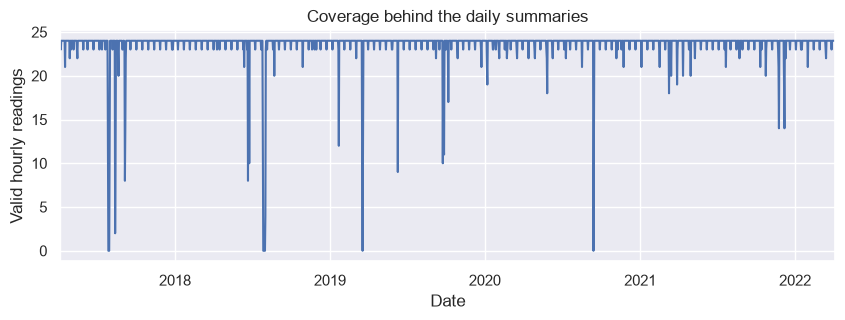

In [26]:
air_daily["count"].plot(
    figsize=(10, 3), title="Coverage behind the daily summaries",
    xlabel="Date", ylabel="Valid hourly readings",
)
plt.show()

**Your turn (3 minutes):** Maya wants to know whether a visible peak was a brief spike or part of several polluted days. Choose its month, select the original hourly PM2.5 with `.loc`, and plot it. Describe what a monthly mean would hide. Check the daily counts too: does a low count justify calling a day clean?

In [27]:
# Select one month and plot its hourly PM2.5 with a title and units.

### Interpolation estimates; it does not observe

Luis wants to know whether we can fill missing readings before averaging. **Linear interpolation** estimates a missing value from nearby observations by assuming a straight-line change. `method="time"` uses elapsed time; ordinary `.interpolate()` uses row positions. They agree on evenly spaced rows, but can differ when timestamps are uneven.

Keep original measurements separate from estimates. A straight line could miss a sharp pollution spike, especially across a long gap. Interpolation cannot explain why a reading is missing or establish that the sensor would have measured the estimated value.

**Your turn (3 minutes):** a sensor records 8 at 08:00 and 20 at 12:00, with a missing reading at 09:00. Estimate the missing value by hand assuming a constant rate of change. Then use `.interpolate(method="time", limit_area="inside")` to create `time_estimate` without changing `uneven_readings`.

`limit_area="inside"` fills only gaps between observed values, leaving leading and trailing gaps unknown. Compare with ordinary `.interpolate()`. Which method uses the unequal elapsed times? Does either estimate become an observation?

In [28]:
uneven_readings = pd.Series(
    [8.0, None, 20.0],
    index=pd.to_datetime(["2024-09-02 08:00", "2024-09-02 09:00", "2024-09-02 12:00"]),
)
# Compute time_estimate and compare with ordinary interpolation.

**Check your reasoning:** The time-based estimate is **11**, one quarter of the four-hour rise from 8 to 20. Ordinary interpolation gives **14** because the missing row is halfway between the observed rows. Both remain estimates. If the missing period contained an unobserved smoke spike, neither straight line would recover it.

## Ask how the measurements were made

The people, equipment, places, and collection practices behind a dataset form its **data setting**. Missing readings might reflect maintenance, calibration, lost connections, vandalism, or equipment changes. These possibilities do not establish what caused a particular gap. A sensor's calibration can also affect recorded values, including how well it captures high concentrations.

Watch Yanni Loukissas discuss collection practices (7:57 to 10:24). Identify one human or technical process that could change our graph. [Open the clip](https://www.youtube.com/watch?v=bUws5GCF3GI&t=477s) if the embed is unavailable.

In [29]:
%%html
<iframe width="640" height="360" src="https://www.youtube-nocookie.com/embed/bUws5GCF3GI?start=477&end=624" title="Yanni Loukissas on data settings, 7:57 to 10:24" allowfullscreen></iframe>

A miniature **datasheet** records the context needed to interpret a dataset. In [*Datasheets for Datasets*](https://arxiv.org/abs/1803.09010), Timnit Gebru and colleagues propose documenting origins and appropriate uses. We can start with three questions:

| Category | Question for the club |
| --- | --- |
| Composition | Which place, dates, units, and readings are represented or absent? |
| Collection and processing | How was the sensor calibrated, what interrupted readings, and were values filled or averaged? |
| Uses | Which historical questions can this file answer, and what would a current ride decision require? |

A chart offers **distant reading** of broad patterns. **Close reading** of particular records, collection practices, and people's experiences adds context. Ask maintainers about a gap rather than assigning it a convenient explanation. One sensor or one person's experience does not automatically represent the whole route.

## Exit ticket: a finding and a question (3 minutes)

Give the club **one finding** supported by a traffic or air-quality chart. Cite its dates, units, and summary, and name a detail that summary hides. Then choose one datasheet category above and write an unanswered question about the collection setting. Explain how its answer could change your recommendation.

Distinguish what the recorded values show from an explanation that still needs evidence. For example, a peak alone does not establish a wildfire's cause, and an empty time slot does not establish that the air was clean or the bridge was quiet.

## Check your understanding

1. What does `.loc["2017-03"]` preserve that a monthly summary does not?
2. How do the units change when hourly crossing counts become weekly sums? Why would a sum be unsuitable for particle concentrations?
3. How does downsampling help us see trends, and what can it hide about a busy hour or pollution spike?
4. Why can a non-missing daily sum still be incomplete? Which calculation helps check its coverage?
5. Why does grouping by month number combine Januaries from different years?
6. What assumption produced the interpolated value at 09:00, and what information would we need to trust it?